# Cluster

> Es un modulo para hacer clusters espaciales 

In [ ]:
#| default_exp cluster_ejemplo

In [24]:
#| hide
from nbdev.showdoc import *

In [3]:
#| hide
#| export 
import matplotlib
import sklearn
import random
import numpy as np
import shapely
from sklearn.cluster import DBSCAN, HDBSCAN, OPTICS, KMeans
import matplotlib.pyplot as plt

In [9]:
#| export

class data_points:
    """Una clase que contiene a los datos"""
    def __init__(self,
                 n,
                 min_x = 0,
                 min_y = 0,
                 max_x= 1,
                 max_y=1,
                 seed= None):
        
        if seed != None:
            random.seed(seed)
        
        self.Points = np.random.uniform(low= min_x, high= max_x, size=(n, 2));
        self.Points =  [shapely.Point(x[0],x[1]) for x in self.Points]
    def get_points(self):
        """Una funcion que para obtener los puntos"""
        return self.Points

    def get_Multypoint(self):
        """Regresa un objeto MultiPoint con los puntos"""
        return shapely.geometry.MultiPoint(self.Points)
    
    def get_X(self):
        """Regresa las coordenadas X"""
        return [x.x for x in self.Points]

    def get_Y(self):
        """Regresa las coordenadas Y"""
        return [x.y for x in self.Points]

    def centroid(self):
        """Regresa el centroide de los puntos """
        return shapely.centroid(self.get_Multypoint())

    def as_array(self):
        """Regresa los puntos como un array"""
        list_arrays = np.array([(geom.xy[0][0], geom.xy[1][0]) for geom in self.Points])
        return list_arrays

    def add_points(self, data_points):
        """Agrega puntos de otra """
        self.Points = self.Points + data_points.Points
        return

In [10]:
#| hide
clase_puntos = data_points(500)
clase_puntos.Points

[<POINT (0.665 0.742)>,
 <POINT (0.271 0.226)>,
 <POINT (0.266 0.641)>,
 <POINT (0.481 0.769)>,
 <POINT (0.21 0.306)>,
 <POINT (0.186 0.7)>,
 <POINT (0.445 0.661)>,
 <POINT (0.787 0.258)>,
 <POINT (0.066 0.999)>,
 <POINT (0.715 0.499)>,
 <POINT (0.249 0.415)>,
 <POINT (0.249 0.48)>,
 <POINT (0.191 0.256)>,
 <POINT (0.729 0.334)>,
 <POINT (0.262 0.812)>,
 <POINT (0.233 0.78)>,
 <POINT (0.353 0.81)>,
 <POINT (0.408 0.355)>,
 <POINT (0.282 0.411)>,
 <POINT (0.033 0.6)>,
 <POINT (0.977 0.926)>,
 <POINT (0.403 0.77)>,
 <POINT (0.056 0.912)>,
 <POINT (0.319 0.155)>,
 <POINT (0.412 0.815)>,
 <POINT (0.623 0.557)>,
 <POINT (0.551 0.436)>,
 <POINT (0.491 0.748)>,
 <POINT (0.584 0.583)>,
 <POINT (0.636 0.874)>,
 <POINT (0.262 0.599)>,
 <POINT (0.418 0.416)>,
 <POINT (0.755 0.058)>,
 <POINT (0.129 0.994)>,
 <POINT (0.95 0.56)>,
 <POINT (0.319 0.019)>,
 <POINT (0.087 0.401)>,
 <POINT (0.471 0.639)>,
 <POINT (0.464 0.268)>,
 <POINT (0.077 0.677)>,
 <POINT (0.682 0.443)>,
 <POINT (0.675 0.37)>,
 <PO

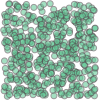

In [12]:
clase_puntos.get_Multypoint()    
    

In [14]:
#| hide 
puntos_simples = data_points(n= 500)

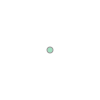

In [15]:
#| hide
puntos_simples.centroid()

In [16]:
#| hide
puntos_simples.get_points()

[<POINT (0.642 0.036)>,
 <POINT (0.545 0.123)>,
 <POINT (0.437 0.843)>,
 <POINT (0.038 0.23)>,
 <POINT (0.389 0.041)>,
 <POINT (0.402 0.238)>,
 <POINT (0.021 0.444)>,
 <POINT (0.147 0.91)>,
 <POINT (0.502 0.795)>,
 <POINT (0.986 0.939)>,
 <POINT (0.717 0.256)>,
 <POINT (0.139 0.328)>,
 <POINT (0.874 0.253)>,
 <POINT (0.53 0.514)>,
 <POINT (0.564 0.878)>,
 <POINT (0.85 0.21)>,
 <POINT (0.322 0.081)>,
 <POINT (0.875 0.042)>,
 <POINT (0.883 0.455)>,
 <POINT (0.223 0.579)>,
 <POINT (0.152 0.775)>,
 <POINT (0.122 0.498)>,
 <POINT (0.408 0.4)>,
 <POINT (0.699 0.668)>,
 <POINT (0.865 0.629)>,
 <POINT (0.051 0.886)>,
 <POINT (0.239 0.569)>,
 <POINT (0.626 0.317)>,
 <POINT (0.026 0.511)>,
 <POINT (0.604 0.871)>,
 <POINT (0.995 0.735)>,
 <POINT (0.685 0.579)>,
 <POINT (0.261 0.821)>,
 <POINT (0.944 0.113)>,
 <POINT (0.283 0.445)>,
 <POINT (0.475 0.583)>,
 <POINT (0.454 0.865)>,
 <POINT (0.953 0.673)>,
 <POINT (0.497 0.29)>,
 <POINT (0.055 0.681)>,
 <POINT (0.757 0.091)>,
 <POINT (0.657 0.449)>,


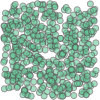

In [17]:
#| hide
puntos_simples.get_Multypoint()

In [18]:
#| hide
puntos_simples.get_X()

[0.641758276042779,
 0.5450057192338513,
 0.4368586684379355,
 0.037639679351611166,
 0.38887420641359016,
 0.4015747090084355,
 0.020718488182770223,
 0.14681184397007196,
 0.5018108048293075,
 0.9863662930505527,
 0.7167169881588318,
 0.1388468745341298,
 0.8735580988414778,
 0.5296047103050863,
 0.5635004743996237,
 0.8504999562489199,
 0.32161456545194034,
 0.8746693581879009,
 0.8830969192137286,
 0.22314394017297978,
 0.15167121929467153,
 0.12179790655116662,
 0.40792490909905266,
 0.6989969612973606,
 0.8653026144138908,
 0.05102891784232322,
 0.23852889104620412,
 0.6257010426558413,
 0.026464641634613262,
 0.6040210141082164,
 0.9946646173720726,
 0.6853781315546535,
 0.2609322131205284,
 0.9435622906139065,
 0.2833057737662341,
 0.4748591971808187,
 0.4538627571903179,
 0.9529858079415975,
 0.49685851563847405,
 0.05477203774457651,
 0.756639885772343,
 0.6572883058831316,
 0.11481405031544467,
 0.32087339757396427,
 0.8855365458823362,
 0.4696810584317038,
 0.91209015870301

In [19]:
#| hide
puntos_simples.get_Y()

[0.03585628178142197,
 0.12255722456998086,
 0.8425785552010211,
 0.22950085160147615,
 0.04094126271475029,
 0.23764565013249184,
 0.44369837244515664,
 0.909922382486376,
 0.7947733981824282,
 0.9394813778614775,
 0.2558746635330992,
 0.32786259186479705,
 0.25253593307732947,
 0.5136250630336244,
 0.8775680628076841,
 0.2103063291279812,
 0.08145501971531521,
 0.042402901861471776,
 0.45454641201620605,
 0.5789488512764983,
 0.7750170424082536,
 0.49758936573642043,
 0.39957648818773583,
 0.6680286143892363,
 0.628917257987471,
 0.885512512965837,
 0.5689646677300656,
 0.3165976886270032,
 0.5112832776483176,
 0.8705318402847235,
 0.7348380182759764,
 0.5787321565465565,
 0.8208531638551073,
 0.11257054739734684,
 0.4453747744986317,
 0.5829621458628006,
 0.8654216643612914,
 0.6725627748619178,
 0.28984826628210203,
 0.6806500254625595,
 0.09144534901447521,
 0.4494264085306662,
 0.20606904191277464,
 0.407529224455331,
 0.7019764719644405,
 0.050133401474513284,
 0.568720442726830

In [21]:
#| hide 
if len(puntos_simples.get_X()) != len(puntos_simples.get_Y()):
    raise Exception("Si hay problema la evaluacion ")

## Clusters

A partir de la clase data_point podemos generar muchos puntos y queremos hacer un agrupamiento de dichos puntos 


In [22]:
#| export 
class Clusters:
  """
  Clase para generar los clusters a partir de un objeto de la clase data_points
  
  Esta clase se utiliza para generar los distintos tipos de clusterizaciones, 
  se almacena los datos en una estructura de datos y se le añaden las respectivas 
  classes
  """
    
  def __init__(self, data_points_i, seed=1234):
    if seed != None:
      random.seed(seed)
      self.data_structure =  data_points_i
    
  def KMeans(self, **kwargs):
    """
    Se usa el algoritmo Kmeans para la obtencion de clusters, 
    las clases quedan almacenadas en .data_structure_classes_Kmeans.
    Si se desea obtener el modelo se tiene que añadir 
    (ret_model = True) como parámetro.
    """
    kmeans_c = KMeans(**kwargs)
    classes_val = kmeans_c.fit_predict(self.data_structure.as_array())
    self.data_structure.classes_Kmeans = classes_val
    
    if 'ret_model' in kwargs and kwargs['ret_model']==True :
        return  kmeans_c
        

  def DBSCAN(self, **kwargs):
    """
    Se DBSCAN para la obtencion de clusters, las clases quedan almacenadas
    en .data_structure_classes_DBSCAN. Si se desea obtener el modelo se tiene
    que añadir (ret_model = True) como parámetro.
    """
    db = DBSCAN(**kwargs).fit(self.data_structure.as_array())
    self.data_structure.classes_DBSCAN = db.labels_
    if 'ret_model' in kwargs and kwargs['ret_model']==True :
        return  db
    
    
  def HDBSCAN(self, **kwargs):
    """
    Se HDBSCAN para la obtencion de clusters, las clases quedan almacenadas
    en .data_structure_classes_HDBSCAN. Si se desea obtener el modelo se tiene
    que añadir (ret_model = True) como parámetro.
    """
    hdb = HDBSCAN(**kwargs).fit(self.data_structure.as_array())
    self.data_structure.classes_HDBSCAN = hdb.labels_
    if 'ret_model' in kwargs and kwargs['ret_model']==True : 
      return  hdb
        

  def OPTICS(self, **kwargs):
    """
    Se usa el algoritmo OPTICS para la obtencion de clusters, 
    las clases quedan almacenadas en .data_structure_classes_OPTICS.
    Si se desea obtener el modelo se tiene que añadir 
    (ret_model = True) como parámetro.
    """
    optics=  OPTICS(**kwargs).fit(self.data_structure.as_array())
    self.data_structure.classes_OPTICS = optics.labels_
    
    if 'ret_model' in kwargs and kwargs['ret_model']==True :
        return  optics

In [25]:
show_doc(Clusters.DBSCAN)

---

### Clusters.DBSCAN

```python
def DBSCAN(
    **kwargs
):
```

*Se DBSCAN para la obtencion de clusters, las clases quedan almacenadas*
en .data_structure_classes_DBSCAN. Si se desea obtener el modelo se tiene
que añadir (ret_model = True) como parámetro.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()